# LightGBM quantile model (mFRR daily and weekly)

Same monthly walk-forward as the baseline and the Ridge. Before each test month, for each `freq × direction`
group, three LightGBM models (p10, p50, p90) are trained on every auction already published
(`src/models/lgbm.py`). The p50 is the prediction; p10 / p90 give the uncertainty.

- **Validation**: a validation period **before 2025**, to compare with the baseline and the Ridge.
- **Evaluation** (from 2025): produced once by `uv run python -m src.models.lgbm`, read at the end (section 7).

LightGBM trains 3 quantiles × 4 groups × 12 months, with the number of trees chosen on the last 3 months of
each training set.

In [38]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.data.data import build_auctions
from src.evaluation import Evaluator
from src.features.build_features import add_model_features, build_features
from src.models import ridge
from src.models.baseline import PreviousKnownAuctionBaseline
from src.models.lgbm import lgbm_quantile_model, to_contract, walk_forward_lgbm
from src.features.build_features import (
    LAG_FEATURES, RATIO_FEATURES, add_lag_features, add_model_features, build_features,  
    OTHER_DIRECTION_FEATURES, WEEKLY_FEATURES, add_other_direction_features, add_weekly_features,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
# team auction table (src/data/data.py), daily + weekly, KORR dropped (see ridge.prepare_auctions)
auctions_all = ridge.prepare_auctions(build_auctions(product="mFRR"), ("daily", "weekly"))
feats = add_model_features(build_features(auctions_all))     # lags + block / day-type one-hots
FEATURE_COLS = ridge.model_feature_columns(feats)

print("model inputs:", FEATURE_COLS)
feats.groupby(["freq", "direction"]).size()

model inputs: ['lag1', 'lag2', 'lag3', 'block_00_04', 'block_04_08', 'block_08_12', 'block_12_16', 'block_16_20', 'block_20_24', 'block_week', 'daytype_saturday', 'daytype_sunday_holiday', 'daytype_week', 'daytype_workday']


freq    direction
daily   downwards    17040
        upwards      17034
weekly  downwards      410
        upwards        410
dtype: int64

## 1. Validation period

Same choice as in `ridge.ipynb`: a period before 2025 whose daily auctions have prices.

In [40]:
a = auctions_all.copy()
a["year"] = a["gc"].dt.year
a.pivot_table(index="year", columns=["freq", "direction"], values="y",
              aggfunc=lambda y: y.isna().mean()).round(2)

freq          daily            weekly        
direction downwards upwards downwards upwards
year                                         
2018           0.00    0.00       NaN     NaN
2019           0.05    0.00       0.0     0.0
2020           0.00    0.06       0.0     0.0
2021           0.11    0.06       0.0     0.0
2022           0.16    0.10       0.0     0.0
2023           0.19    0.12       0.0     0.0
2024           0.90    0.83       0.0     0.0
2025           0.00    0.00       0.0     0.0
2026           0.03    0.00       0.0     0.0

In [41]:
VAL_START, VAL_LAST_DAY = "2022-01-01", "2024-12-31"
VAL_END = (pd.Timestamp(VAL_LAST_DAY) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # exclusive end, for the Evaluator

in_val = (auctions_all["gc"] >= pd.Timestamp(VAL_START, tz="UTC")) & (auctions_all["gc"] < pd.Timestamp(VAL_END, tz="UTC"))
print(VAL_START, "to", VAL_LAST_DAY, ":", in_val.sum(), "auctions,", auctions_all.loc[in_val, "y"].notna().sum(), "with a price")

2022-01-01 to 2024-12-31 : 13064 auctions, 8349 with a price


## 2. Walk-forward on the validation period

LightGBM with the default target `delta` = y − lag1.

In [42]:
preds_lgbm = walk_forward_lgbm(feats, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS)
print(len(preds_lgbm), "auctions predicted")

13064 auctions predicted


In [43]:
RIDGE_VARIANT = "ridge_allfeats_delta"      # the best variant of ridge.ipynb
ridge_variants = {
    "ridge_lags3":          dict(feature_cols=ridge.FEATURES, target="level"),
    "ridge_lags3_delta":    dict(feature_cols=ridge.FEATURES, target="delta"),
    "ridge_allfeats_delta": dict(feature_cols=FEATURE_COLS, target="delta"),
    "ridge_lags3_delta_per_series": dict(feature_cols=ridge.FEATURES, target="delta", group_cols=["series"]),
}
preds_ridge = ridge.walk_forward_ridge(feats, start_test=VAL_START, end_test=VAL_LAST_DAY, **ridge_variants[RIDGE_VARIANT])

## 3. The four groups: LightGBM vs Ridge vs baseline

In [44]:
baseline = PreviousKnownAuctionBaseline().fit(auctions_all)
contracts = {
    "baseline": baseline.predict(auctions_all[in_val]),
    RIDGE_VARIANT: ridge.to_contract(preds_ridge, RIDGE_VARIANT),
    "lgbm_quantile": to_contract(preds_lgbm),
}
evaluator = Evaluator(actuals=auctions_all, start_test=VAL_START, end_test=VAL_END)
report = evaluator.evaluate_many(contracts)

report.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3)

model             baseline  lgbm_quantile  ridge_allfeats_delta
freq   direction                                               
daily  downwards     0.228          0.201                 0.209
       upwards       0.292          0.239                 0.267
weekly downwards     0.106          0.099                 0.107
       upwards       0.040          0.036                 0.039

In [45]:
# full report: n, MAE, RMSE, pinball of each quantile and coverage of [p10, p90] (ideal 0.80)
cols = [c for c in ["model", "freq", "direction", "n", "mae", "rmse", "pinball_q10", "pinball_q50", "pinball_q90", "coverage_80"]
        if c in report.columns]
report[cols].sort_values(["freq", "direction", "model"]).round(3)

,model,freq,direction,n,mae,rmse,pinball_q10,pinball_q50,pinball_q90,coverage_80
0,baseline,daily,downwards,3791,0.228,0.353,None,None,None,None
8,lgbm_quantile,daily,downwards,3791,0.201,0.312,0.041648,0.100473,0.064426,0.762332
4,ridge_allfeats_delta,daily,downwards,3791,0.209,0.314,0.049008,0.104586,0.067499,0.843841
1,baseline,daily,upwards,4244,0.292,0.460,None,None,None,None
9,lgbm_quantile,daily,upwards,4244,0.239,0.382,0.051163,0.119531,0.070615,0.7705
5,ridge_allfeats_delta,daily,upwards,4244,0.267,0.372,0.0595,0.133392,0.074673,0.877474
2,baseline,weekly,downwards,157,0.106,0.163,None,None,None,None
10,lgbm_quantile,weekly,downwards,157,0.099,0.164,0.024492,0.049605,0.036925,0.732484
6,ridge_allfeats_delta,weekly,downwards,157,0.107,0.160,0.023316,0.053308,0.035905,0.757962
3,baseline,weekly,upwards,157,0.040,0.062,None,None,None,None


In [46]:
rows = {}
for name, p, col in [("baseline", preds_lgbm, "pred_baseline"), (RIDGE_VARIANT, preds_ridge, "pred_ridge"),
                     ("lgbm_quantile", preds_lgbm, "pred_lgbm")]:
    s = p[p["y"].notna()]
    rows[name] = (s[col] - s["y"]).abs().groupby([s["gc"].dt.year, s["freq"], s["direction"]]).mean()
pd.DataFrame(rows).round(3)

baseline  ridge_allfeats_delta  lgbm_quantile
gc   freq   direction                                               
2022 daily  downwards     0.235                 0.220          0.210
            upwards       0.337                 0.317          0.276
     weekly downwards     0.119                 0.120          0.116
            upwards       0.049                 0.047          0.043
2023 daily  downwards     0.218                 0.194          0.188
            upwards       0.247                 0.215          0.200
     weekly downwards     0.073                 0.073          0.061
            upwards       0.026                 0.027          0.023
2024 daily  downwards     0.253                 0.243          0.231
            upwards       0.293                 0.271          0.246
     weekly downwards     0.126                 0.127          0.120
            upwards       0.046                 0.044          0.043

## 4. Number of trees chosen

For each month, group and quantile, `walk_forward_lgbm` chooses the number of trees on the last 3 months of the
training data.

In [47]:
tuning = preds_lgbm.attrs["tuning"]
tuning.groupby(["freq", "direction", "quantile"])["n_estimators"].value_counts().unstack(fill_value=0)

n_estimators               100  300  600
freq   direction quantile               
daily  downwards 0.1        17    5   14
                 0.5        30    4    2
                 0.9        20    2   14
       upwards   0.1        13   11   12
                 0.5        14   10   12
                 0.9        23   12    1
weekly downwards 0.1        36    0    0
                 0.5        36    0    0
                 0.9        36    0    0
       upwards   0.1        36    0    0
                 0.5        36    0    0
                 0.9        36    0    0

## 5. Feature Importance

One p50 model per group, trained on everything published before the validation period. The importance is related to the number of
times a feature is used in a split.

In [48]:
importance = {}
before = feats[feats["avail"] < VAL_START].dropna(subset=["y", "lag1"])
for (freq, direction), d in before.groupby(["freq", "direction"]):
    model = lgbm_quantile_model(0.5, 300).fit(d[FEATURE_COLS], d["y"] - d["lag1"])
    importance[f"{freq} {direction}"] = pd.Series(model.feature_importances_, index=FEATURE_COLS)

pd.DataFrame(importance).sort_values("daily downwards", ascending=False)

,daily downwards,daily upwards,weekly downwards,weekly upwards
lag1,1245,1187,58,60
lag3,1233,1268,131,150
lag2,1187,1198,111,90
daytype_workday,104,119,0,0
block_00_04,78,106,0,0
block_04_08,69,42,0,0
block_08_12,67,56,0,0
block_12_16,49,64,0,0
block_16_20,45,37,0,0
daytype_sunday_holiday,42,35,0,0


## 5. Quantiles and bidding

Pay-as-bid: a bid is accepted only if it is at or below the marginal price.
- `share_below_p10`: how often the actual price fell below the p10 (ideal is approximately 0.10);

In [49]:
p = preds_lgbm[preds_lgbm["y"].notna()]
groups = [p["freq"], p["direction"]]

calibration = pd.DataFrame({
    "coverage_p10_p90": ((p["y"] >= p["p10_lgbm"]) & (p["y"] <= p["p90_lgbm"])).groupby(groups).mean(),
    "share_below_p10": (p["y"] < p["p10_lgbm"]).groupby(groups).mean(),
    "share_above_p90": (p["y"] > p["p90_lgbm"]).groupby(groups).mean(),
    "mean_width_p10_p90": (p["p90_lgbm"] - p["p10_lgbm"]).groupby(groups).mean(),
})
calibration.round(3)

coverage_p10_p90  share_below_p10  share_above_p90  \
freq   direction                                                       
daily  downwards             0.762            0.104            0.134   
       upwards               0.770            0.072            0.157   
weekly downwards             0.732            0.153            0.115   
       upwards               0.841            0.108            0.051   

                  mean_width_p10_p90  
freq   direction                      
daily  downwards               0.526  
       upwards                 0.693  
weekly downwards               0.270  
       upwards                 0.175

In [50]:
bids = {"baseline (lag1)": "pred_baseline", "lgbm p50": "p50_lgbm", "lgbm p10": "p10_lgbm"}
perfect = (10 ** p["y"]).groupby(groups).sum()
rows = {}
for name, col in bids.items():
    accepted = p[col] <= p["y"]
    revenue = (10 ** p[col]).where(accepted, 0.0)
    rows[(name, "share_rejected")] = (~accepted).groupby(groups).mean()
    rows[(name, "revenue_share")] = revenue.groupby(groups).sum() / perfect
pd.DataFrame(rows).T.round(3)

freq                               daily            weekly        
direction                      downwards upwards downwards upwards
baseline (lag1) share_rejected     0.607   0.638     0.669   0.694
                revenue_share      0.294   0.178     0.285   0.281
lgbm p50        share_rejected     0.492   0.399     0.592   0.522
                revenue_share      0.418   0.341     0.329   0.462
lgbm p10        share_rejected     0.104   0.072     0.153   0.108
                revenue_share      0.420   0.382     0.599   0.785

## 6. Using one series and one month

Actual price, baseline and LightGBM p50 with the p10–p90 band. 

29 auctions, 7 without a price


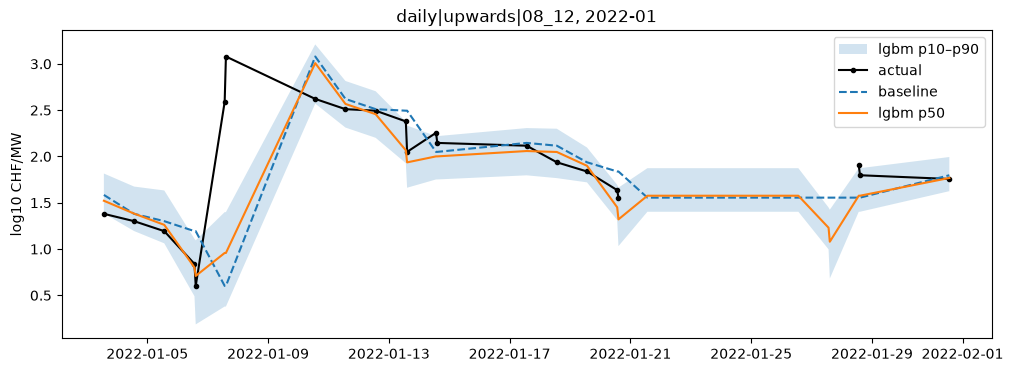

In [51]:
SERIES = "daily|upwards|08_12"
MONTH = VAL_START[:7]

start = pd.Timestamp(MONTH, tz="UTC")
end = start + pd.offsets.MonthBegin(1)
s = preds_lgbm[(preds_lgbm["series"] == SERIES) & (preds_lgbm["gc"] >= start) & (preds_lgbm["gc"] < end)]
print(len(s), "auctions,", s["y"].isna().sum(), "without a price")

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(s["gc"], s["p10_lgbm"], s["p90_lgbm"], alpha=0.2, label="lgbm p10–p90")
ax.plot(s["gc"], s["y"], "k.-", label="actual")
ax.plot(s["gc"], s["pred_baseline"], "--", label="baseline")
ax.plot(s["gc"], s["p50_lgbm"], "-", label="lgbm p50")
ax.set_ylabel("log10 CHF/MW")
ax.set_title(f"{SERIES}, {MONTH}")
ax.legend()
plt.show()

## 7. Adding Features

In [ ]:
feats_x = add_lag_features(feats)
FEATURE_COLS_X = FEATURE_COLS + LAG_FEATURES

feats_r = add_lag_features(add_model_features(build_features(auctions_all, ratio_lags=1)))
FEATURE_COLS_R = FEATURE_COLS_X + RATIO_FEATURES

feats_o = add_other_direction_features(feats_x, auctions_all)
feats_w = add_weekly_features(feats_x, auctions_all)
FEATURE_COLS_O = FEATURE_COLS_X + OTHER_DIRECTION_FEATURES
FEATURE_COLS_W = FEATURE_COLS_X + WEEKLY_FEATURES

feats_w[WEEKLY_FEATURES + OTHER_DIRECTION_FEATURES[:0]].describe()

,weekly_lag1,weekly_gap
count,34856.000000,34856.000000
mean,2.754535,1.702061
std,0.552790,0.676933
min,1.455758,-0.405322
25%,2.322219,1.331227
50%,2.703291,1.719451
75%,3.139123,2.106629
max,4.250486,4.765917


In [53]:
preds_lgbm_x = walk_forward_lgbm(feats_x, start_test=VAL_START, end_test=VAL_LAST_DAY,
                                 feature_cols=FEATURE_COLS_X)
preds_lgbm_r = walk_forward_lgbm(feats_r, start_test=VAL_START, end_test=VAL_LAST_DAY,
                                 feature_cols=FEATURE_COLS_R)
preds_lgbm_o = walk_forward_lgbm(feats_o, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS_O)
preds_lgbm_w = walk_forward_lgbm(feats_w, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS_W)

In [54]:
contracts_x = {
    "baseline": contracts["baseline"],
    "lgbm_quantile": contracts["lgbm_quantile"],            # o modelo atual
    "lgbm_lagfeats": to_contract(preds_lgbm_x, "lgbm_lagfeats"),
}
report_x = evaluator.evaluate_many(contracts_x)
report_x.pivot_table(index=["freq", "direction"], columns="model",
                     values=["mae", "pinball_q10", "coverage_80"]).round(3)

coverage_80                    mae                \
model            lgbm_lagfeats lgbm_quantile baseline lgbm_lagfeats   
freq   direction                                                      
daily  downwards      0.759958      0.762332    0.228         0.200   
       upwards         0.77262        0.7705    0.292         0.235   
weekly downwards      0.713376      0.732484    0.106         0.098   
       upwards        0.853503      0.840764    0.040         0.036   

                                 pinball_q10                
model            lgbm_quantile lgbm_lagfeats lgbm_quantile  
freq   direction                                            
daily  downwards         0.201       0.04063      0.041648  
       upwards           0.239      0.050014      0.051163  
weekly downwards         0.099      0.020266      0.024492  
       upwards           0.036      0.007308      0.007796

In [55]:
contracts_r = {
    "baseline": contracts["baseline"],
    "lgbm_quantile": contracts["lgbm_quantile"],
    "lgbm_lagfeats": to_contract(preds_lgbm_x, "lgbm_lagfeats"),
    "lgbm_ratio": to_contract(preds_lgbm_r, "lgbm_ratio"),
}
report_r = evaluator.evaluate_many(contracts_r)
report_r.pivot_table(index=["freq", "direction"], columns="model",
                     values=["mae", "pinball_q10", "coverage_80"]).round(3)

coverage_80                               mae  \
model            lgbm_lagfeats lgbm_quantile lgbm_ratio baseline   
freq   direction                                                   
daily  downwards      0.759958      0.762332   0.756792    0.228   
       upwards         0.77262        0.7705   0.772149    0.292   
weekly downwards      0.713376      0.732484   0.681529    0.106   
       upwards        0.853503      0.840764   0.828025    0.040   

                                                          pinball_q10  \
model            lgbm_lagfeats lgbm_quantile lgbm_ratio lgbm_lagfeats   
freq   direction                                                        
daily  downwards         0.200         0.201      0.199       0.04063   
       upwards           0.235         0.239      0.238      0.050014   
weekly downwards         0.098         0.099      0.097      0.020266   
       upwards           0.036         0.036      0.036      0.007308   

                                           
model            lgbm_quantile lgbm_ratio  
freq   direction                           
daily  downwards      0.041648   0.040726  
       upwards        0.051163   0.049591  
weekly downwards      0.024492   0.020366  
       upwards        0.007796   0.007334

In [56]:
contracts_c = {
    "baseline": contracts["baseline"],
    "lgbm_lagfeats": to_contract(preds_lgbm_x, "lgbm_lagfeats"),
    "lgbm_otherdir": to_contract(preds_lgbm_o, "lgbm_otherdir"),
    "lgbm_weekly": to_contract(preds_lgbm_w, "lgbm_weekly"),
}
report_c = evaluator.evaluate_many(contracts_c)
report_c.pivot_table(index=["freq", "direction"], columns="model",
                     values=["mae", "pinball_q10", "coverage_80"]).round(3)

coverage_80                                mae  \
model            lgbm_lagfeats lgbm_otherdir lgbm_weekly baseline   
freq   direction                                                    
daily  downwards      0.759958      0.759166    0.741757    0.228   
       upwards         0.77262      0.786287    0.754006    0.292   
weekly downwards      0.713376      0.700637    0.719745    0.106   
       upwards        0.853503      0.853503    0.847134    0.040   

                                                           pinball_q10  \
model            lgbm_lagfeats lgbm_otherdir lgbm_weekly lgbm_lagfeats   
freq   direction                                                         
daily  downwards         0.200         0.198       0.200       0.04063   
       upwards           0.235         0.226       0.230      0.050014   
weekly downwards         0.098         0.098       0.098      0.020266   
       upwards           0.036         0.036       0.036      0.007308   

                                            
model            lgbm_otherdir lgbm_weekly  
freq   direction                            
daily  downwards      0.040416    0.040671  
       upwards        0.047618    0.047058  
weekly downwards      0.019757    0.020265  
       upwards        0.007281    0.007234

## 7. Final result on the test period (from 2025)

Read from the files written by `uv run python -m src.models.baseline`, `... src.models.ridge` and
`... src.models.lgbm`. Do not use these numbers to change the models.

In [57]:
RESULTS = Path("../results")
files = sorted(RESULTS.glob("metrics_*.parquet"))
if files:
    final = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    display(final.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3))
    if "coverage_80" in final:
        display(final.pivot_table(index=["freq", "direction"], columns="model", values="coverage_80").round(3))
else:
    print("no metrics_*.parquet in results/: run the baseline, ridge and lgbm scripts first")

no metrics_*.parquet in results/: run the baseline, ridge and lgbm scripts first
